# Syllables on the photometry PSTH grid

What is the mouse doing, syllable by syllable, at each moment of the photometry PSTHs in `4_ddm_hmm_photometry.ipynb`? The goal is to find which syllables go with the neuromodulator signal: see *Which syllables go with the neuromodulator signal?* below.

- **Same grid, same masks.** The syllable states files are binned at 30 Hz on the same session clock as the photometry (`goCueTrigger_times` agree exactly). The code of each trial is read at the same −1 to +1 s around stimulus onset and around feedback, in real time with no time-warping, and the same per-trial masks are applied. Everything is shared through `Functions/event_psth.py`.
- **Syllables**: left paw + wheel, k = 8, the same run the trial modes were built from. code = paw + 8·whisk + 16·lick. Paw states are numbered by vigor (0 = stillest) and coloured with the run's own `state_palette.csv`, where violet means left-paw-led and teal means wheel-led.
- **Units.** Probabilities are taken per session over trials with a valid code at that sample, then averaged over sessions. The across-kind figure then gives each mouse equal weight.

In [1]:
import sys, pathlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'event_psth.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'paper-individuality'))
from Functions import ddm_hmm as dh
from Functions import event_psth as ep
import paper_style as ps
ps.use('paper')
warnings.filterwarnings('ignore', message='Mean of empty slice')
warnings.filterwarnings('ignore', message='Degrees of freedom')
warnings.filterwarnings('ignore', message='invalid value encountered')

DATA = REPO / 'paper-individuality' / 'data' / 'neuromodulators'
RUN = 'left_paw_wheel_k8_own_lick-100ms'
STATES_DIR = DATA / f'states_files_{RUN}'
cfg = json.loads((STATES_DIR / '_config.json').read_text())
assert cfg['relabel'] is None, 'paw digits are relabelled in this run: map them first'
PALETTE = pd.read_csv(pathlib.Path(cfg['states_dir']) / 'state_palette.csv', index_col='state')
N_PAW = len(PALETTE)
PAW_COLORS = PALETTE['colour'].tolist()
VIGOR = PALETTE['vigor'].to_numpy()          # z-scored wavelet power per paw state, the vigor axis

K, EXCLUDE, MIN_TRIALS = 4, ['ZFM-06271'], 20
trials, params = dh.load_all(K)
labels = dh.state_labels(trials, params)
d = dh.go_trials(trials)
d = d[~d['subject'].isin(EXCLUDE)].merge(labels[['subject', 'state', 'label', 'tag']], on=['subject', 'state'])
rec = pd.read_csv(dh.ARCHIVE / 'recordings.csv')
rec = rec[rec['eid'].isin(d['eid'])]

STIM, FB, meta = ep.photometry_windows(rec, d)              # photometry, for the reference row
SYL_S, SYL_F = ep.syllable_windows(meta, STATES_DIR)         # syllable codes, same rows and grid
TIME, QP = ep.TIME, float(meta['quiescencePeriod'].median())
valid = lambda X, drop: np.isnan(X) & ~np.isnan(drop)
print(f'{len(meta):,} trials; samples with a photometry value but no syllable code: '
      f'{valid(SYL_S, STIM).sum() / (~np.isnan(STIM)).sum():.1%} (stim window), '
      f'{valid(SYL_F, FB).sum() / (~np.isnan(FB)).sum():.1%} (feedback window)')
miss = (valid(SYL_S, STIM).sum(1) + valid(SYL_F, FB).sum(1)) / np.maximum((~np.isnan(STIM)).sum(1) + (~np.isnan(FB)).sum(1), 1)
print('missing syllable codes among unmasked samples, by mouse:', meta.assign(miss=miss).groupby('subject')['miss'].mean().round(3).to_dict())

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


190,223 trials; samples with a photometry value but no syllable code: 1.0% (stim window), 3.5% (feedback window)
missing syllable codes among unmasked samples, by mouse: {'ZFM-04019': 0.016, 'ZFM-08776': 0.08, 'ZFM-08818': 0.046, 'ZFM-08871': 0.01, 'ZFM-09365': 0.004, 'ZFM-09394': 0.007, 'ZFM-09439': 0.02}


## Per-trial features and per-session averages

Every sample of every trial is turned into features:
- one-hot paw state (8);
- whisking (0/1);
- licking (0/1);
- **paw vigor**, the vigor value of that paw state from the palette table.

`session_mean` averages a feature over trials within each session. It returns one row per session, keeping the stimulus and feedback windows side by side.

In [2]:
paw_s, whisk_s, lick_s = ep.decode(SYL_S, N_PAW)
paw_f, whisk_f, lick_f = ep.decode(SYL_F, N_PAW)

def vigor_of(paw):
    out = np.full(paw.shape, np.nan, dtype=np.float32)
    ok = ~np.isnan(paw)
    out[ok] = VIGOR[paw[ok].astype(int)]
    return out

FEATURES = {
    'paw vigor': (vigor_of(paw_s), vigor_of(paw_f)),
    'P(whisking)': (whisk_s, whisk_f),
    'P(licking)': (lick_s, lick_f),
    **{f'P(paw {k})': (np.where(np.isnan(paw_s), np.nan, paw_s == k), np.where(np.isnan(paw_f), np.nan, paw_f == k))
       for k in range(N_PAW)},
    'photometry': (STIM, FB),
}

def session_mean(m, feature):
    # (sessions x time) for each window: per-session mean over trials of m
    Xs, Xf = FEATURES[feature]
    rows = [(eid, np.nanmean(Xs[g.index], 0), np.nanmean(Xf[g.index], 0))
            for eid, g in m.groupby('eid') if len(g) >= MIN_TRIALS]
    if not rows:
        return None
    eids, s, f = zip(*rows)
    return pd.Index(eids), np.vstack(s), np.vstack(f)

sem = lambda X: np.nanstd(X, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(X), axis=0))

## Photometry and syllables together, per neuromodulator

Each block covers one neuromodulator and one outcome, and pools every trial of those mice (all DDM states). The rows are:
1. the photometry PSTH (mean ± SEM across sessions);
2. the paw-state composition, stacked from stillest (top, pale) to most vigorous (bottom, dark);
3. P(whisking) as a band and P(licking) as a line.

The same epoch edges sit on every row.

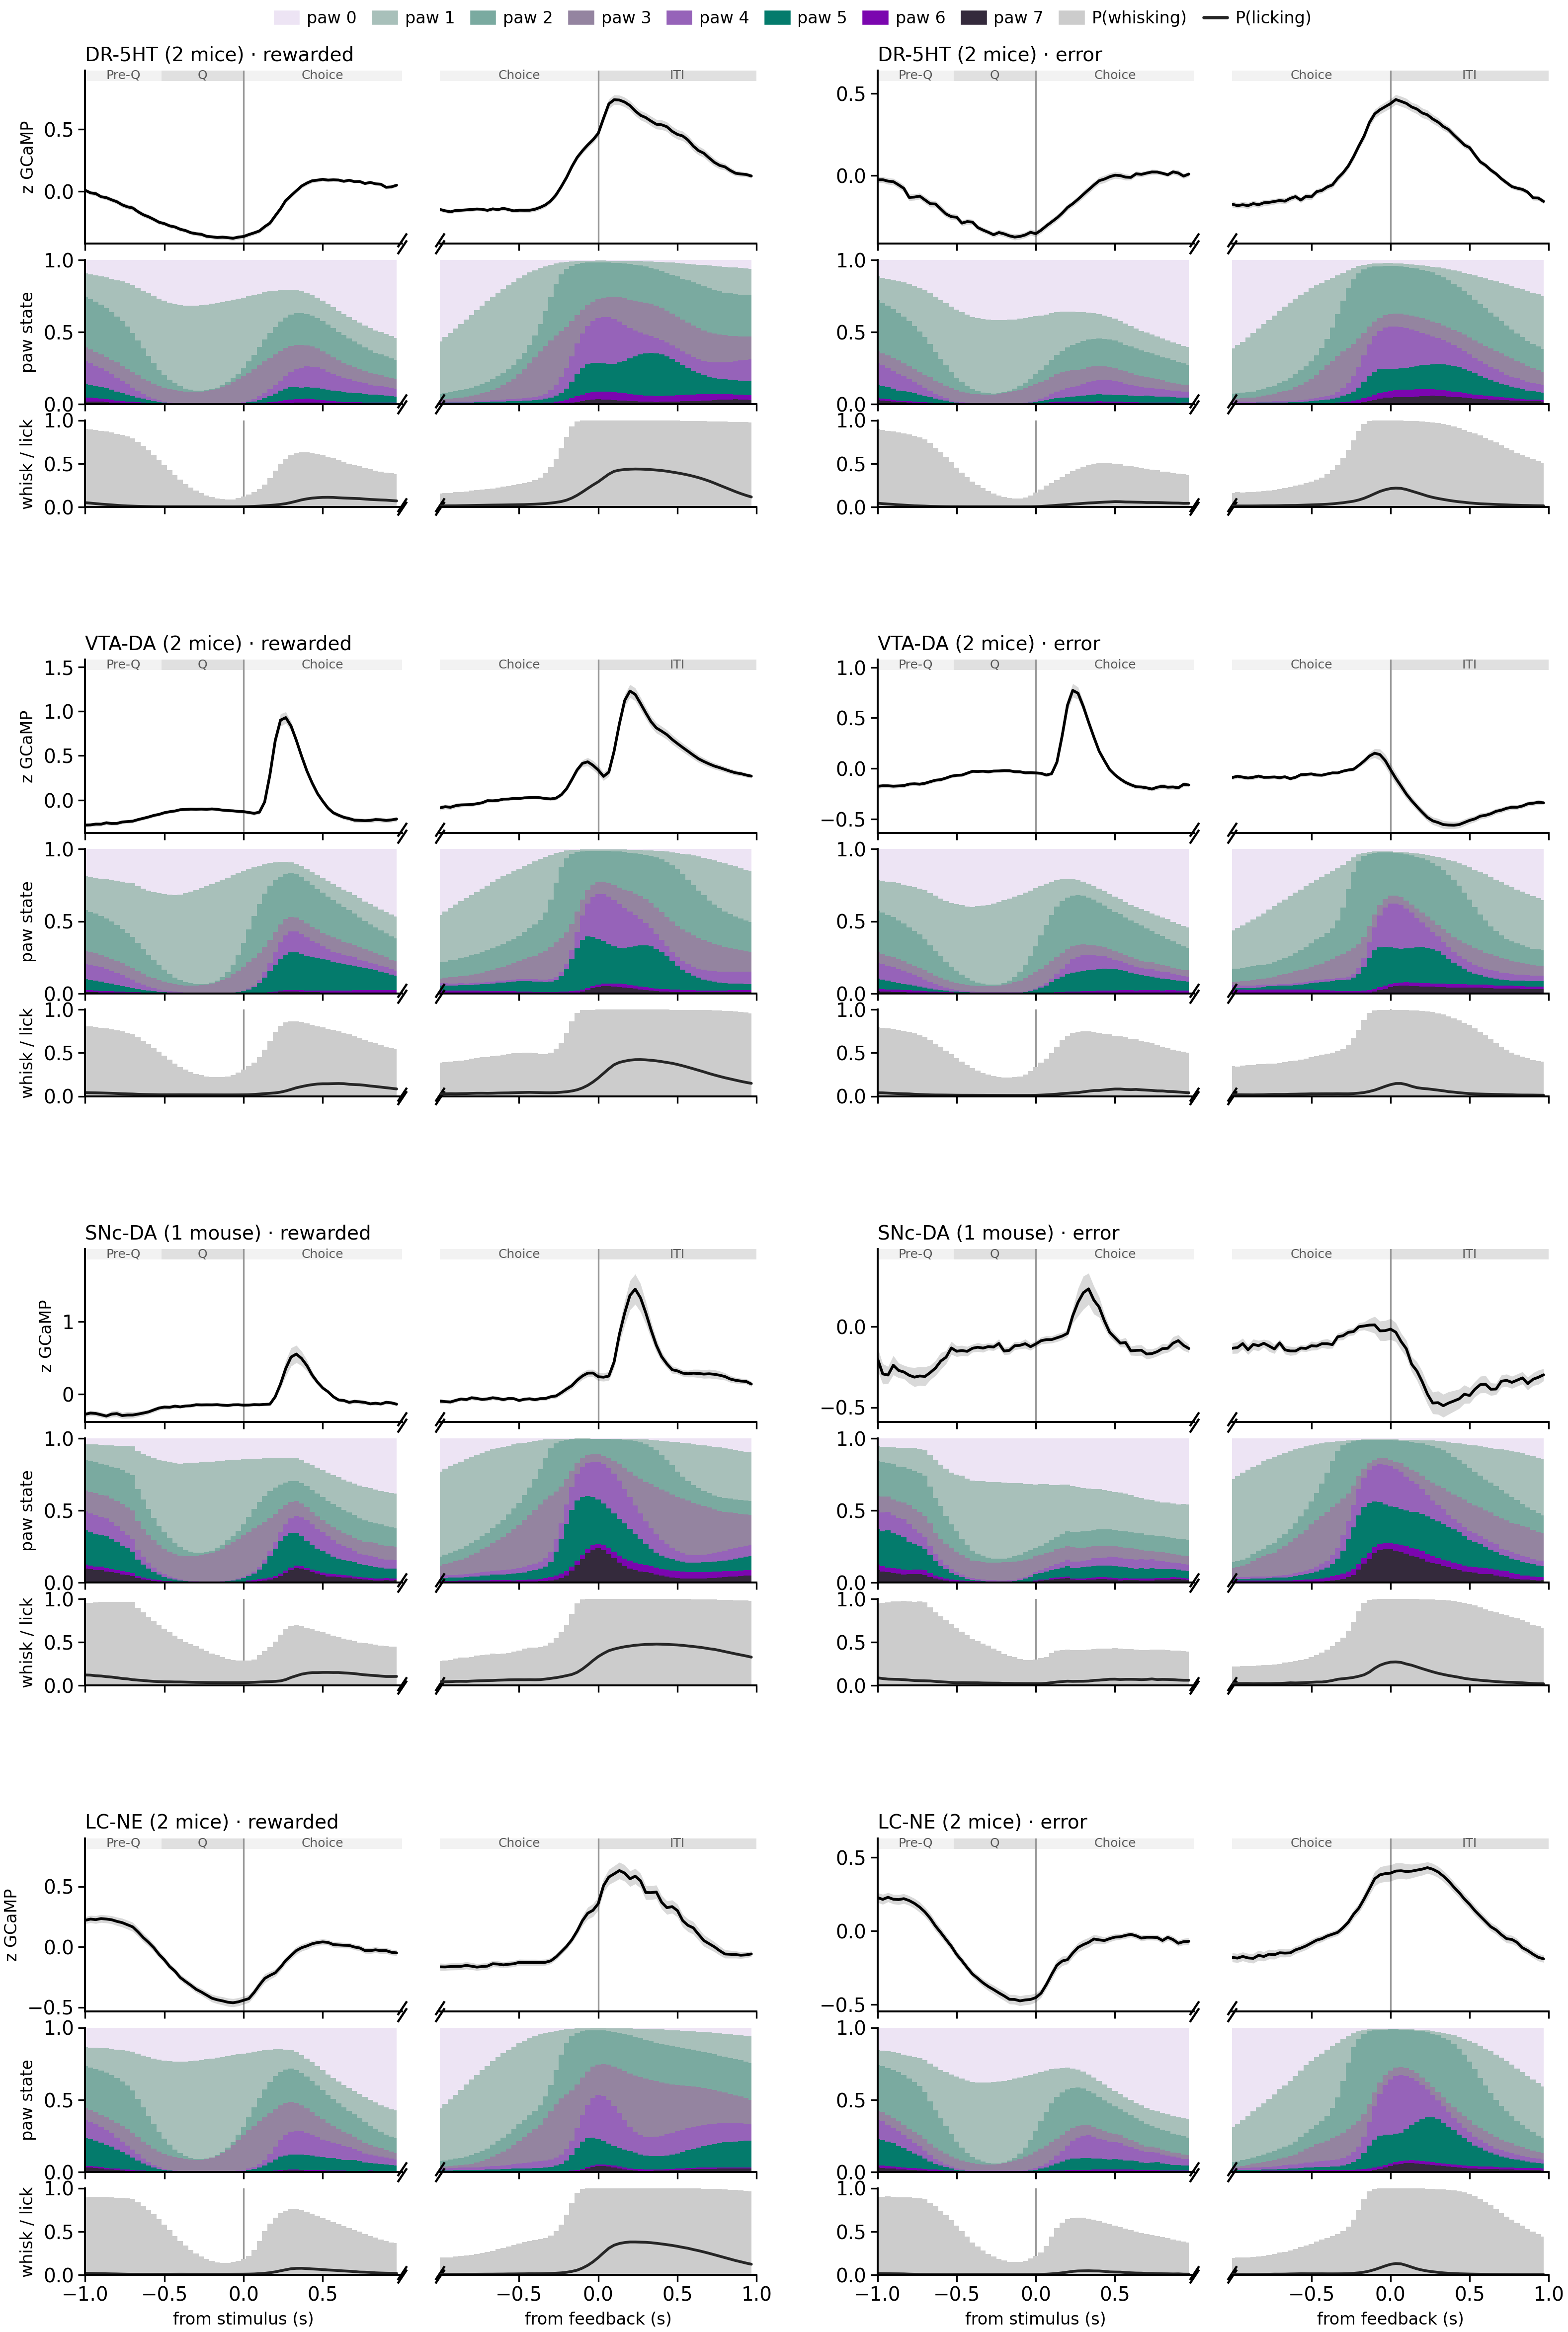

In [3]:
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE']

def composition(m):
    # mean over sessions of per-session paw-state fractions: (n_paw, T) per window
    comp_s, comp_f = [], []
    for k in range(N_PAW):
        r = session_mean(m, f'P(paw {k})')
        comp_s.append(np.nanmean(r[1], 0)); comp_f.append(np.nanmean(r[2], 0))
    cs, cf = np.vstack(comp_s), np.vstack(comp_f)
    return cs / cs.sum(0, keepdims=True), cf / cf.sum(0, keepdims=True)

def stack(ax, comp):
    top = np.ones(len(TIME))
    for k in range(N_PAW):     # stillest at the top
        ax.fill_between(TIME, top - comp[k], top, color=PAW_COLORS[k], lw=0, step='mid')
        top = top - comp[k]
    ax.set_ylim(0, 1)

fig = plt.figure(figsize=(9.5, 3.6 * len(NM_ORDER)))
outer = fig.add_gridspec(len(NM_ORDER), 2, wspace=0.18, hspace=0.35)
for row, nm in enumerate(NM_ORDER):
    nmice = meta.loc[meta['target_NM'] == nm, 'subject'].nunique()
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[(meta['target_NM'] == nm) & (meta['correct'] == outcome)]
        block = outer[row, col].subgridspec(3, 1, height_ratios=[1.2, 1, 0.6], hspace=0.12)
        title = f"{nm} ({nmice} {'mouse' if nmice == 1 else 'mice'}) · {oname}"
        a, b = ep.split_panels(fig, block[0], title, epochs=True, qp=QP, xlabels=False)
        _, S, F = session_mean(m, 'photometry')
        for ax, X in [(a, S), (b, F)]:
            mu, se = np.nanmean(X, 0), sem(X)
            ax.fill_between(TIME, mu - se, mu + se, color='k', alpha=0.15, lw=0); ax.plot(TIME, mu, color='k', lw=1)
        ep.share_ylim(a, b)
        if col == 0:
            a.set_ylabel('z GCaMP', fontsize=6)
        cs, cf = composition(m)
        a2, b2 = ep.split_panels(fig, block[1], epochs=False, xlabels=False)
        stack(a2, cs); stack(b2, cf)
        if col == 0:
            a2.set_ylabel('paw state', fontsize=6)
        a3, b3 = ep.split_panels(fig, block[2], epochs=False, xlabels=(row == len(NM_ORDER) - 1))
        for ax, w in [(a3, 0), (b3, 1)]:
            wk = np.nanmean(session_mean(m, 'P(whisking)')[1 + w], 0)
            lk = np.nanmean(session_mean(m, 'P(licking)')[1 + w], 0)
            ax.fill_between(TIME, 0, wk, color='0.8', lw=0, step='mid'); ax.plot(TIME, lk, color='0.15', lw=1)
            ax.set_ylim(0, 1)
        if col == 0:
            a3.set_ylabel('whisk / lick', fontsize=6)
handles = [Patch(color=PAW_COLORS[k], label=f'paw {k}') for k in range(N_PAW)] + \
          [Patch(color='0.8', label='P(whisking)'), Line2D([], [], color='0.15', label='P(licking)')]
fig.legend(handles=handles, loc='upper center', ncol=10, frameon=False, fontsize=6, bbox_to_anchor=(0.5, 0.905))
plt.show()

## Which syllables go with the neuromodulator signal?

The question here is **trial-to-trial**: at a fixed moment of the PSTH, do trials with more of a given syllable have a higher or lower NM signal? This differs from comparing the average curves above, where both signals follow the trial's structure and would correlate trivially.

**Method**
- **Per sample.** For each session, outcome and time sample, I compute the Pearson correlation across trials between the photometry value and a syllable indicator (1 if the trial is in that syllable at that moment, 0 otherwise). This is a point-biserial r. Because time is fixed, the shared time course drops out.
- **Exclusions.** A sample needs at least `MIN_TRIALS` trials with both values, and at least `MIN_EVENTS` trials on each side of the indicator. Otherwise it is left blank.
- **Averaging.** r is Fisher-z averaged over each mouse's sessions, then across that neuromodulator's mice with each mouse weighted equally, and converted back to r.
- **Dots** mark samples where the session-level z values differ from 0 at FDR q < 0.05 *and* every mouse of that neuromodulator has the same sign. The t-test treats sessions as units, so it overstates certainty when there are only 1–2 mice. The dots are a guide to where to look, not a test.

**Two views**
1. **Factored**: the 8 paw states, whisking and licking, each as its own indicator.
2. **Full syllables**: all paw × whisk × lick combinations that take at least 1% of samples.

**Confounds.** Across trials, both signals also co-vary with RT, contrast and engagement. A slow, disengaged trial is both still-pawed and low-dopamine, for example. Outcome is split here. Partialling out RT and contrast is the natural next control.

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t

/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


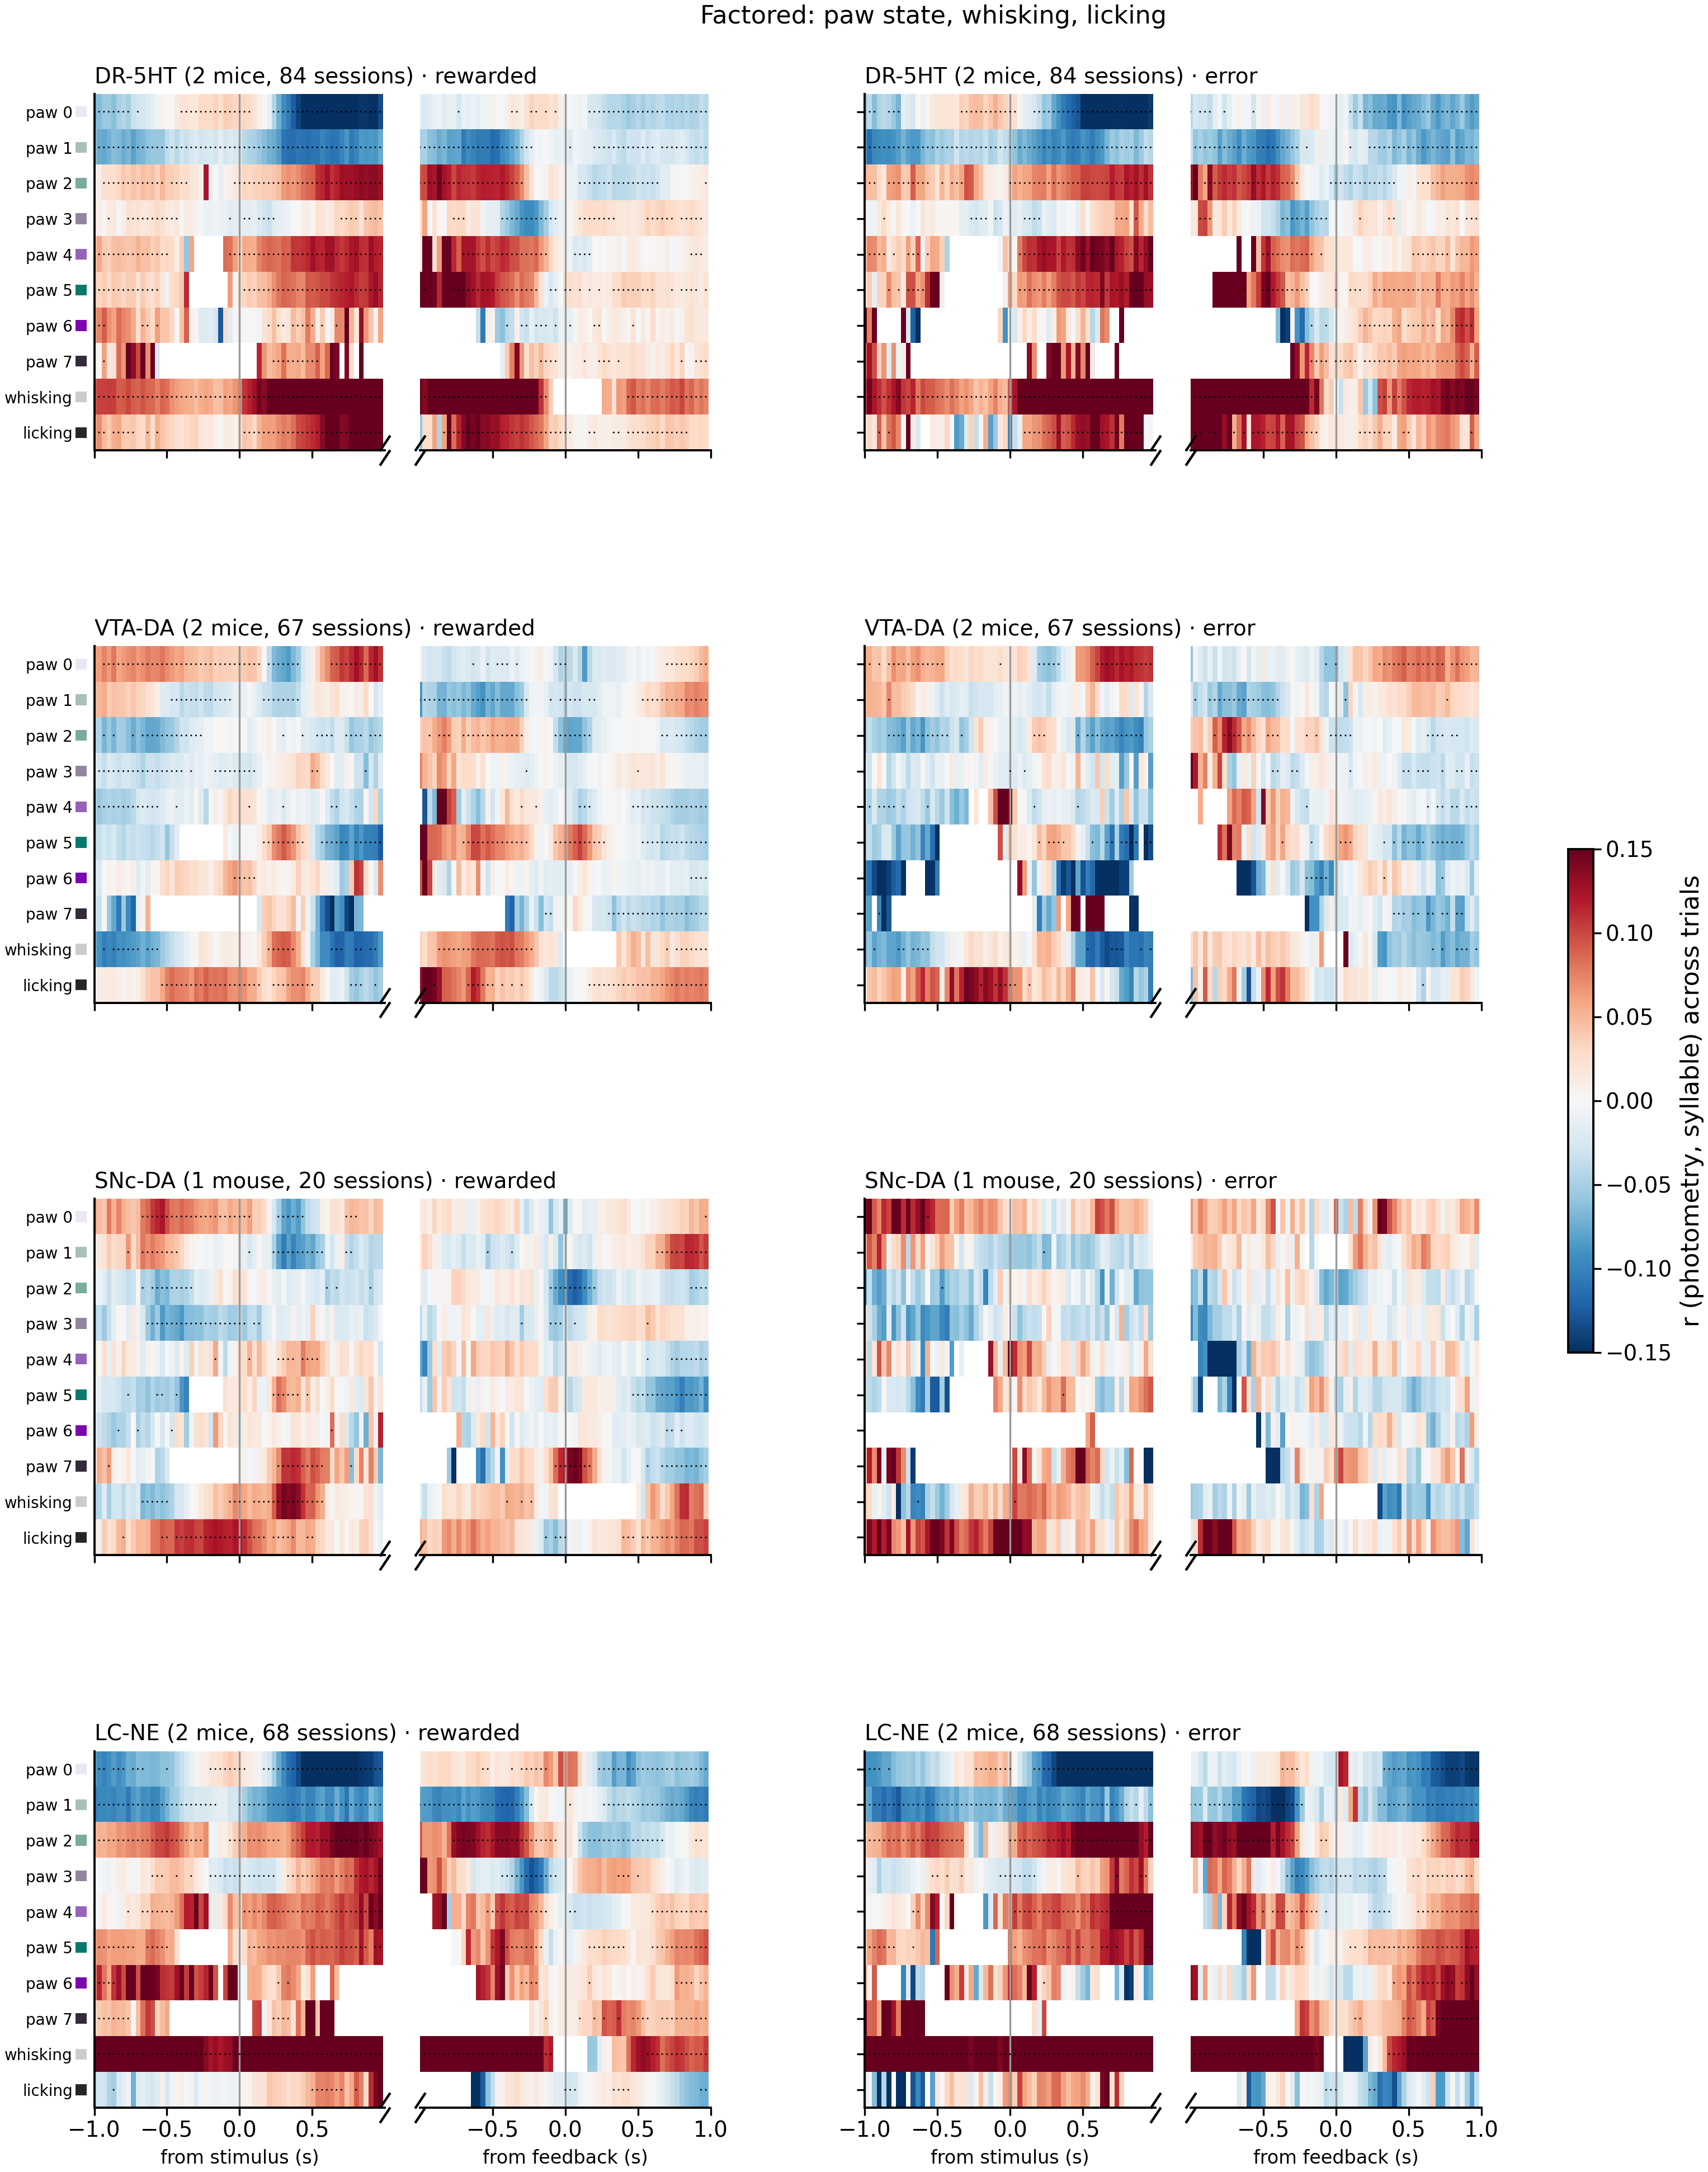

In [4]:
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests

MIN_EVENTS = 5

def nan_corr(X, Y):
    # column-wise Pearson r over rows where both are finite; NaN where too few rows or no variance
    M = ~np.isnan(X) & ~np.isnan(Y)
    n = M.sum(0)
    with np.errstate(invalid='ignore', divide='ignore'):
        mx = np.where(M, X, 0).sum(0) / n; my = np.where(M, Y, 0).sum(0) / n
        dx = np.where(M, X - mx, 0); dy = np.where(M, Y - my, 0)
        r = (dx * dy).sum(0) / np.sqrt((dx ** 2).sum(0) * (dy ** 2).sum(0))
        ones = np.where(M, Y, 0).sum(0)
    r[(n < MIN_TRIALS) | (ones < MIN_EVENTS) | (n - ones < MIN_EVENTS)] = np.nan
    return r

def indicators(kind):
    # name -> (stim, fb) binary arrays (NaN where no code)
    out = {}
    if kind == 'factored':
        for k in range(N_PAW):
            out[f'paw {k}'] = FEATURES[f'P(paw {k})']
        out['whisking'], out['licking'] = FEATURES['P(whisking)'], FEATURES['P(licking)']
    else:
        codes = np.concatenate([SYL_S[~np.isnan(SYL_S)], SYL_F[~np.isnan(SYL_F)]]).astype(int)
        share = np.bincount(codes, minlength=4 * N_PAW) / len(codes)
        order = sorted(np.flatnonzero(share >= 0.01), key=lambda c: (c // (2 * N_PAW), (c // N_PAW) % 2, c % N_PAW))
        for c in order:
            name = f"paw {c % N_PAW}" + (' +W' if (c // N_PAW) % 2 else '') + (' +L' if c // (2 * N_PAW) else '')
            out[name] = (np.where(np.isnan(SYL_S), np.nan, SYL_S == c), np.where(np.isnan(SYL_F), np.nan, SYL_F == c))
    return out

def correlation_maps(kind):
    # (nm, outcome) -> dict(r=(F x T stim, F x T fb), sig=(...)), plus feature names
    ind = indicators(kind)
    names = list(ind)
    res = {}
    for (nm, outcome), m in meta.groupby(['target_NM', 'correct']):
        z = {w: {mouse: [] for mouse in m['subject'].unique()} for w in (0, 1)}
        for (mouse, eid), g in m.groupby(['subject', 'eid']):
            idx = g.index.to_numpy()
            for w, P in enumerate((STIM, FB)):
                Z = np.vstack([np.arctanh(np.clip(nan_corr(P[idx], ind[f][w][idx].astype(float)), -0.999, 0.999))
                               for f in names])
                z[w][mouse].append(Z)
        out_r, out_sig = [], []
        for w in (0, 1):
            per_mouse = {mm: np.nanmean(np.stack(v), 0) for mm, v in z[w].items() if v}
            mouse_mean = np.nanmean(np.stack(list(per_mouse.values())), 0)
            sessions = np.concatenate([np.stack(v) for v in z[w].values() if v])
            t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
            p = np.asarray(p, float)
            ok = ~np.isnan(p)
            q = np.full(p.shape, np.nan); q[ok] = multipletests(p[ok], method='fdr_bh')[1]
            signs = np.sign(np.stack(list(per_mouse.values())))
            agree = np.all(signs == np.sign(mouse_mean)[None], axis=0)
            out_r.append(np.tanh(mouse_mean)); out_sig.append((q < 0.05) & agree)
        res[(nm, outcome)] = dict(r=out_r, sig=out_sig, n_mice=len(per_mouse), n_sessions=len(sessions))
    return res, names

def plot_maps(res, names, row_colors=None, lim=0.15, title=''):
    fig = plt.figure(figsize=(10, (0.16 * len(names) + 0.75) * len(NM_ORDER) + 0.6))
    outer = fig.add_gridspec(len(NM_ORDER), 2, wspace=0.25, hspace=0.55, top=0.95, bottom=0.05)
    h = (TIME[1] - TIME[0]) / 2
    for row, nm in enumerate(NM_ORDER):
        for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
            r = res[(nm, outcome)]
            a, b = ep.split_panels(fig, outer[row, col],
                                   f"{nm} ({r['n_mice']} {'mouse' if r['n_mice'] == 1 else 'mice'}, "
                                   f"{r['n_sessions']} sessions) · {oname}",
                                   epochs=False, xlabels=(row == len(NM_ORDER) - 1))
            for ax, R, S in [(a, r['r'][0], r['sig'][0]), (b, r['r'][1], r['sig'][1])]:
                im = ax.imshow(R, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim,
                               extent=(TIME[0] - h, TIME[-1] + h, len(names) - 0.5, -0.5), interpolation='nearest')
                yy, xx = np.nonzero(S)
                ax.scatter(TIME[xx], yy, s=1.2, c='k', marker='.', lw=0)
                ax.set_xlim(-1, 1); ax.set_ylim(len(names) - 0.5, -0.5)
            a.set_yticks(range(len(names)), names if col == 0 else [], fontsize=5)
            if row_colors is not None and col == 0:
                a.scatter(np.full(len(names), -1.09), range(len(names)), marker='s', s=12, c=row_colors, clip_on=False)
                a.tick_params(axis='y', pad=7, length=0)
    fig.colorbar(im, ax=fig.axes, shrink=0.25, label='r (photometry, syllable) across trials')
    fig.suptitle(title, fontsize=8, y=0.99)
    plt.show()

res_f, names_f = correlation_maps('factored')
plot_maps(res_f, names_f, row_colors=PAW_COLORS + ['0.8', '0.15'], title='Factored: paw state, whisking, licking')

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t

/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')
/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/tmp/ipykernel_15439/1723673263.py:52: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(sessions, 0, axis=0, nan_policy='omit')


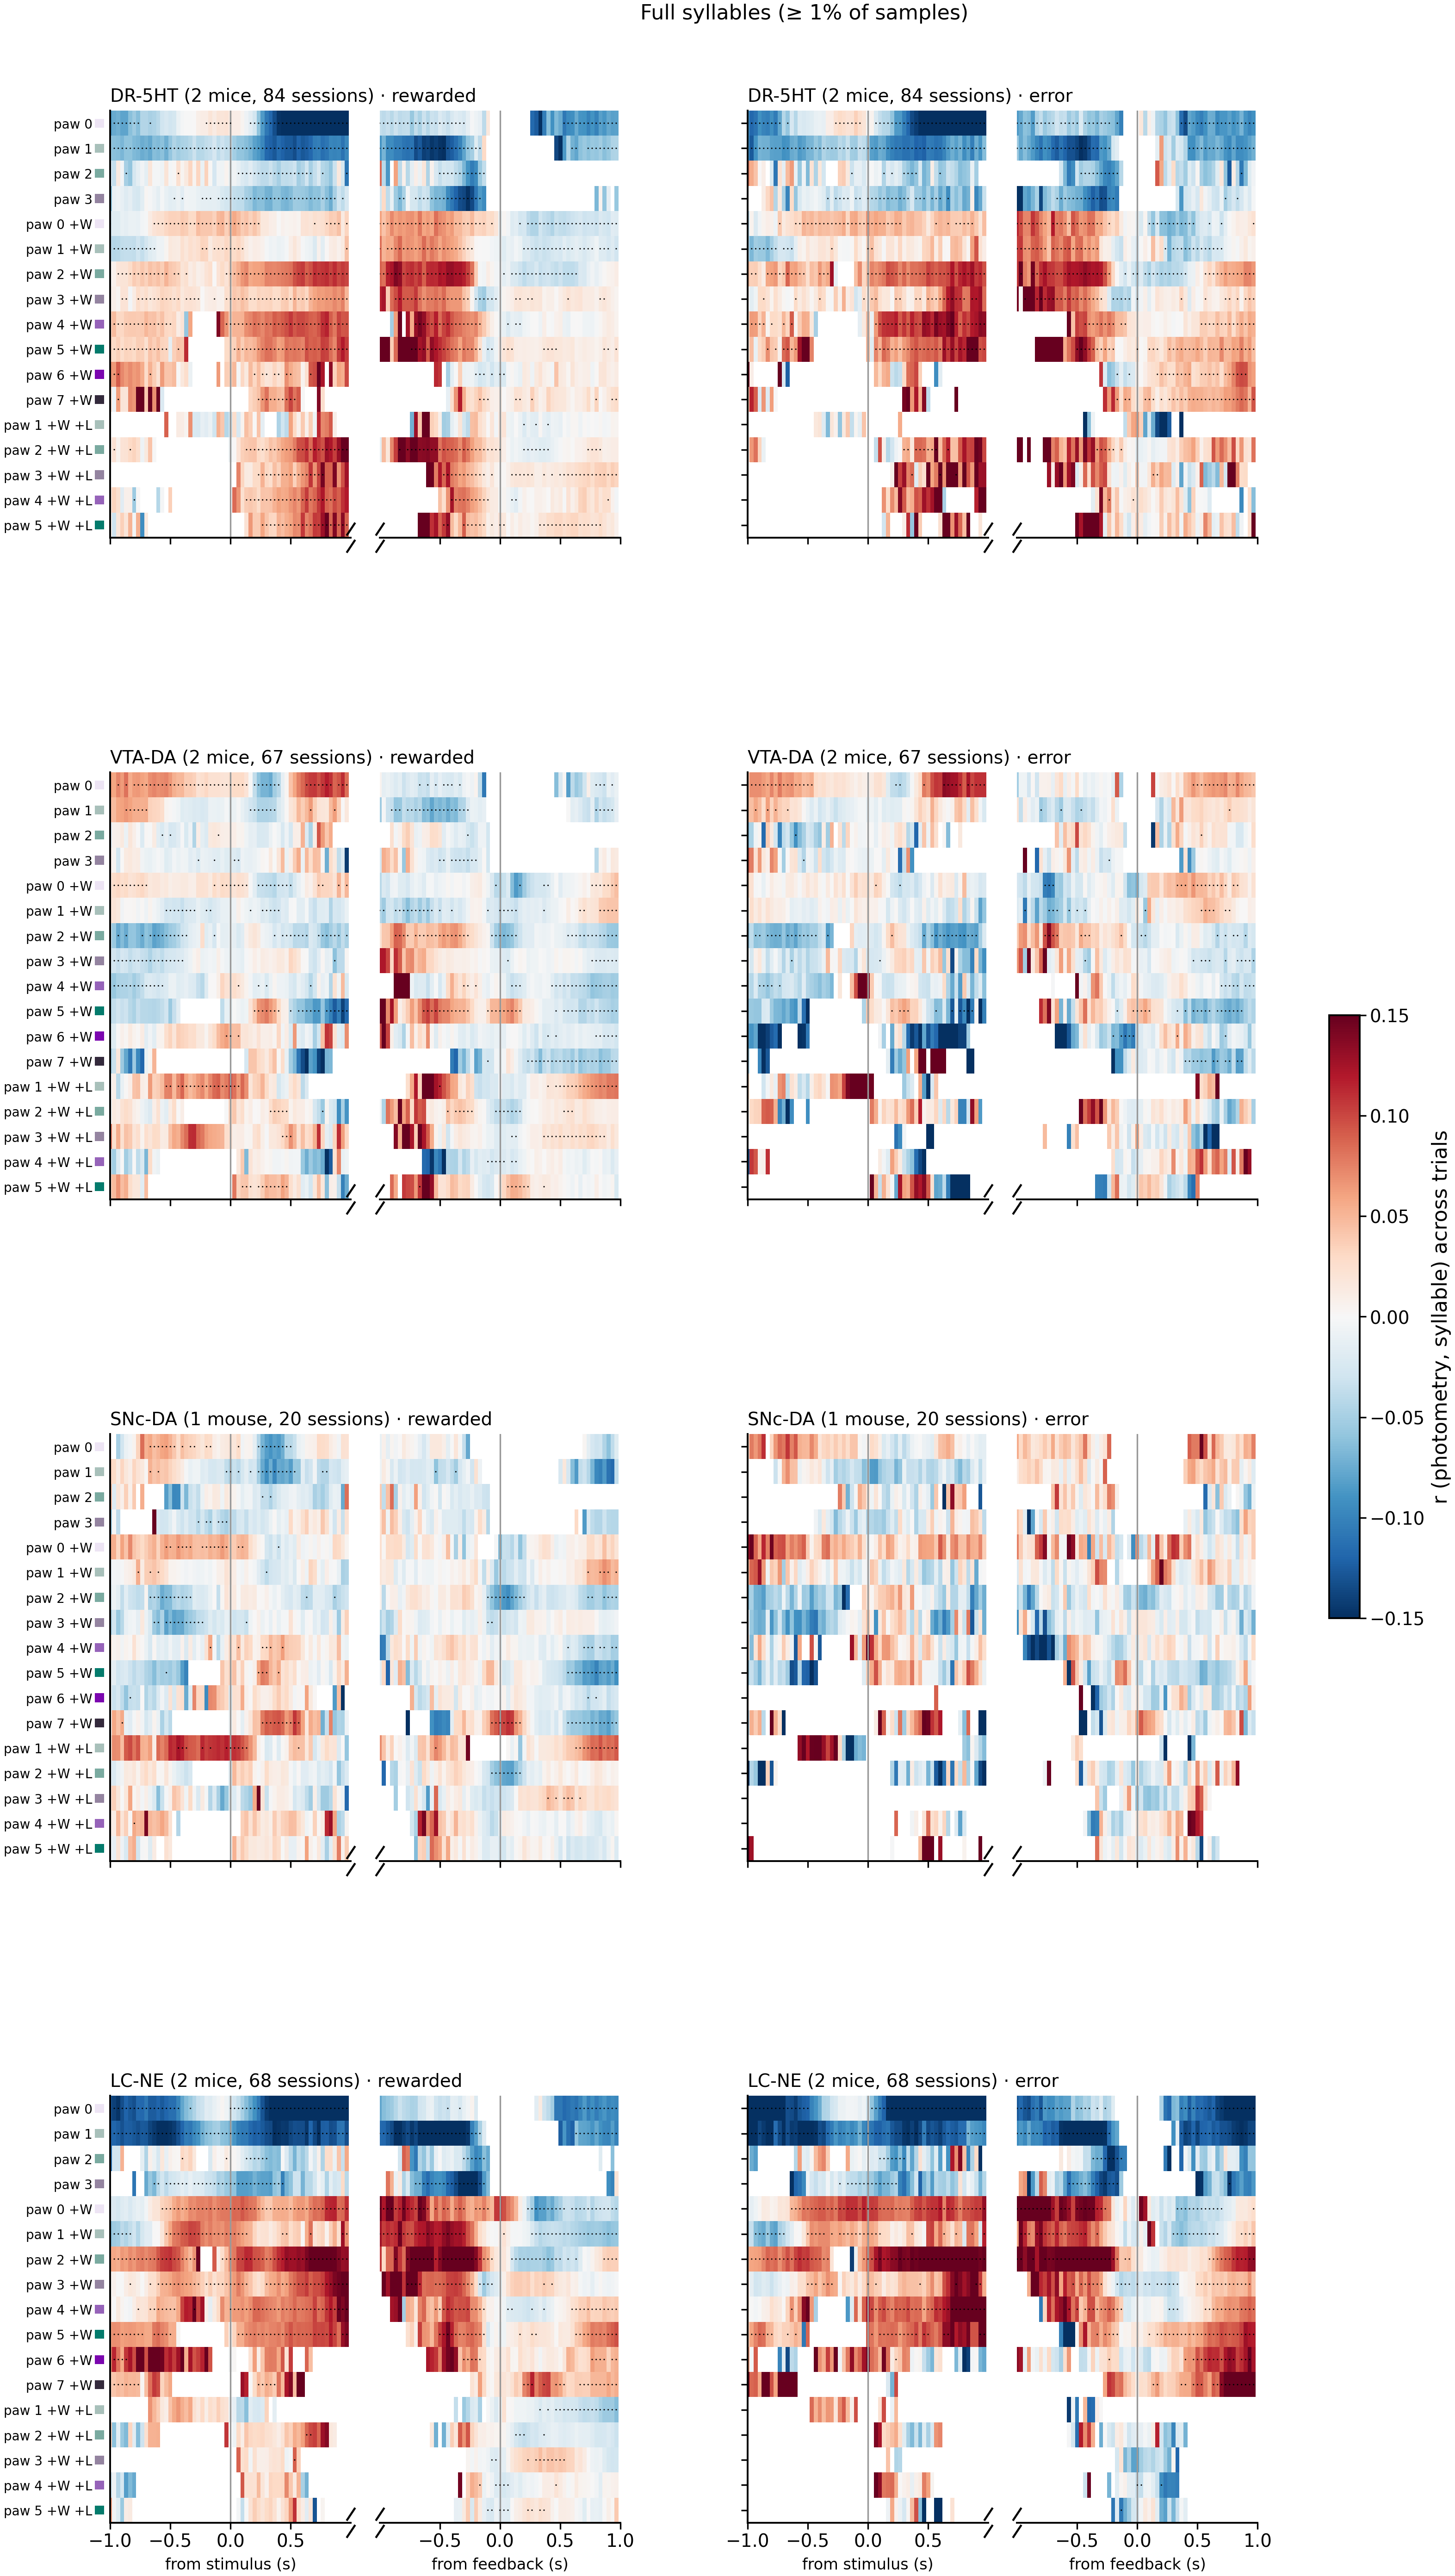

In [5]:
res_s, names_s = correlation_maps('syllables')
paw_of = [int(n.split()[1]) for n in names_s]
plot_maps(res_s, names_s, row_colors=[PAW_COLORS[k] for k in paw_of], title='Full syllables (≥ 1% of samples)')

### Where in the PSTH the strongest relations sit

For each neuromodulator and outcome, the table lists the feature–sample pairs with the largest |r| that are marked (FDR plus same sign in every mouse), from the factored view.

In [6]:
rows = []
for (nm, outcome), r in res_f.items():
    for w, wname in enumerate(['stim', 'fb']):
        R, S = r['r'][w], r['sig'][w]
        for fi, ti in zip(*np.nonzero(S)):
            rows.append({'NM': nm, 'outcome': 'rewarded' if outcome == 1 else 'error', 'window': wname,
                         'time (s)': TIME[ti], 'feature': names_f[fi], 'r': R[fi, ti]})
top = pd.DataFrame(rows)
(top.assign(absr=top['r'].abs()).sort_values('absr', ascending=False)
    .groupby(['NM', 'outcome', 'feature']).head(1)          # each feature's peak once
    .groupby(['NM', 'outcome']).head(4).drop(columns='absr')
    .sort_values(['NM', 'outcome', 'r']).round(3).reset_index(drop=True))

,NM,outcome,window,time (s),feature,r
0,DR-5HT,error,stim,0.700,paw 0,-0.179
1,DR-5HT,error,stim,0.867,paw 5,0.190
2,DR-5HT,error,fb,-0.833,licking,0.251
3,DR-5HT,error,stim,0.600,whisking,0.275
4,DR-5HT,rewarded,stim,0.567,paw 0,-0.185
5,DR-5HT,rewarded,fb,-0.800,licking,0.193
6,DR-5HT,rewarded,fb,-0.700,paw 5,0.207
7,DR-5HT,rewarded,stim,0.600,whisking,0.296
8,LC-NE,error,fb,0.967,paw 7,0.246
9,LC-NE,error,stim,0.900,paw 4,0.248


## The same syllable features, one line per DDM-HMM state kind

This uses all 7 mice. Each state kind's per-session mean is averaged within mouse, then across mice. The band is SEM across mice where a kind exists in 2 or more mice; otherwise it is SEM across that one mouse's sessions, drawn as a dashed outline. The legend gives the number of mice per kind. The rows are paw vigor, P(still paw = state 0), P(whisking), P(licking) and, for reference, the photometry deviation from the session mean (as in notebook 4).

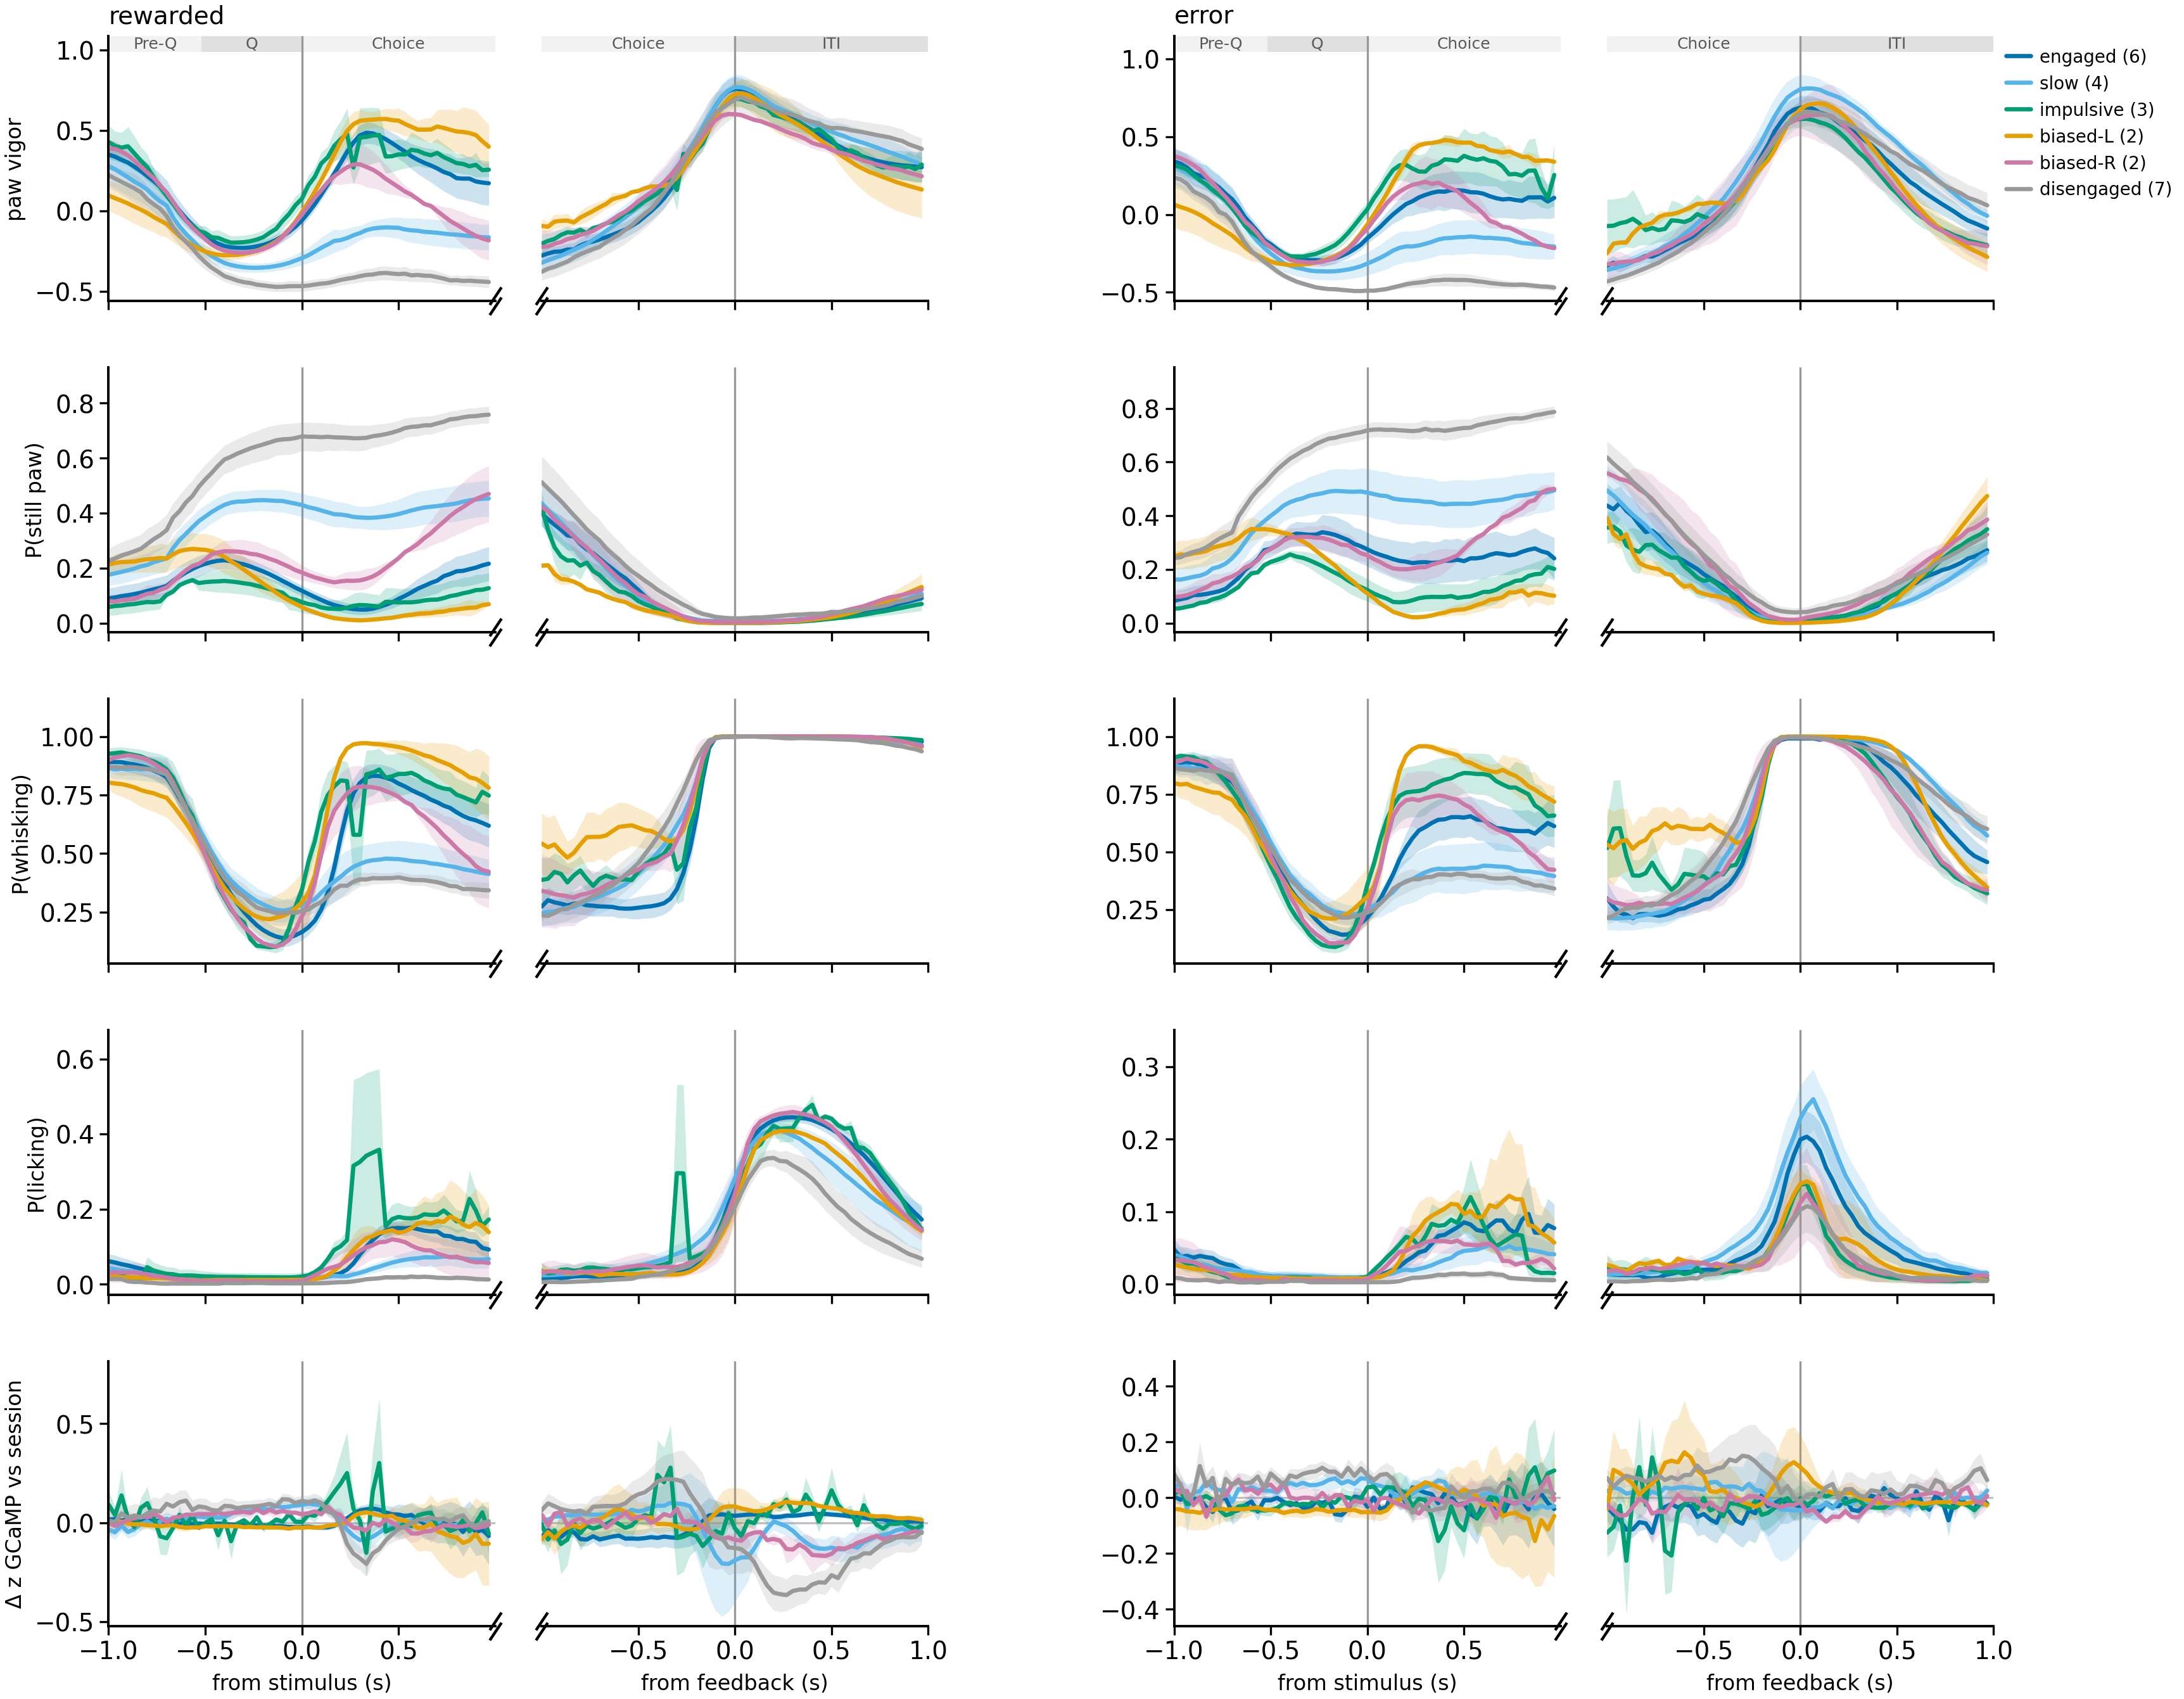

In [7]:
def kind_traces(m, feature, deviation=False):
    # kind -> (stim mu, stim se, fb mu, fb se, n_mice, across)
    out = {}
    for kind in [k for k in dh.LABEL_COLORS if k in set(m['label'])]:
        per_mouse_s, per_mouse_f, sess_s, sess_f = [], [], {}, {}
        for mouse, gm in m.groupby('subject'):
            rows_s, rows_f = [], []
            for eid, g in gm.groupby('eid'):
                gk = g[g['label'] == kind]
                if len(gk) < MIN_TRIALS:
                    continue
                Xs, Xf = FEATURES[feature]
                s, f = np.nanmean(Xs[gk.index], 0), np.nanmean(Xf[gk.index], 0)
                if deviation:
                    s, f = s - np.nanmean(Xs[g.index], 0), f - np.nanmean(Xf[g.index], 0)
                rows_s.append(s); rows_f.append(f)
            if rows_s:
                sess_s[mouse], sess_f[mouse] = np.vstack(rows_s), np.vstack(rows_f)
                per_mouse_s.append(np.nanmean(sess_s[mouse], 0)); per_mouse_f.append(np.nanmean(sess_f[mouse], 0))
        if len(per_mouse_s) >= 2:
            S, F = np.vstack(per_mouse_s), np.vstack(per_mouse_f)
            out[kind] = (np.nanmean(S, 0), sem(S), np.nanmean(F, 0), sem(F), len(S), 'mice')
        elif per_mouse_s:
            (mouse,) = sess_s
            S, F = sess_s[mouse], sess_f[mouse]
            if len(S) >= 2:
                out[kind] = (np.nanmean(S, 0), sem(S), np.nanmean(F, 0), sem(F), 1, 'sessions')
    return out

ROWS = [('paw vigor', 'paw vigor', False), ('P(paw 0)', 'P(still paw)', False), ('P(whisking)', 'P(whisking)', False),
        ('P(licking)', 'P(licking)', False), ('photometry', 'Δ z GCaMP vs session', True)]
fig = plt.figure(figsize=(9.6, 1.55 * len(ROWS) + 0.4))
outer = fig.add_gridspec(len(ROWS), 2, wspace=0.3, hspace=0.25)
for row, (feature, ylab, dev) in enumerate(ROWS):
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[meta['correct'] == outcome]
        a, b = ep.split_panels(fig, outer[row, col], oname if row == 0 else None, epochs=(row == 0), qp=QP,
                               xlabels=(row == len(ROWS) - 1))
        tr = kind_traces(m, feature, deviation=dev)
        for kind, (ms, ss, mf, sf, n, across) in tr.items():
            c = dh.LABEL_COLORS[kind]
            for ax, mu, se in [(a, ms, ss), (b, mf, sf)]:
                if across == 'mice':
                    ax.fill_between(TIME, mu - se, mu + se, color=c, alpha=0.2, lw=0)
                else:
                    ax.plot(TIME, mu - se, color=c, lw=0.5, ls='--'); ax.plot(TIME, mu + se, color=c, lw=0.5, ls='--')
                ax.plot(TIME, mu, color=c, lw=1.2)
        if dev:
            for ax in (a, b):
                ax.axhline(0, color='0.75', lw=0.6, zorder=0)
        ep.share_ylim(a, b)
        if col == 0:
            a.set_ylabel(ylab, fontsize=6)
        if row == 0 and col == 1:
            b.legend(handles=[Line2D([], [], color=dh.LABEL_COLORS[k], lw=1.2, ls='-' if tr[k][5] == 'mice' else '--',
                                     label=f'{k} ({tr[k][4]})') for k in tr],
                     fontsize=5, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

## Notes

- **Masked samples are the same as for the photometry.** The late stimulus window and the early feedback window are dominated by slow trials, so differences there between state kinds partly come from RT composition. This applies to the syllables exactly as it does to the photometry.
- **Paw vigor** is the vigor value of the paw state (z-scored wavelet power, from `state_palette.csv`). It is a convenient one-line summary. The full composition is in the stacked rows.
- **Licking** comes from a 100 ms lick HMM, so its edges are blurred by about 100 ms.